In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D2/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'UniqueMappingClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'UniqueMappingClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'UniqueMappingClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'UniqueMappingClustering_scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with UniqueMappingClustering,1051,0.20,cosine,88.58,87.50,88.04,931,120,943,133,cosine,[name],1024,0,1,salted_qgrams,,4
1,Clustering with UniqueMappingClustering,1038,0.30,cosine,89.02,86.84,87.92,924,114,936,140,cosine,[name],1024,0,1,salted_qgrams,,4
2,Clustering with UniqueMappingClustering,1006,0.40,cosine,89.76,84.87,87.25,903,103,915,161,cosine,[name],1024,0,1,salted_qgrams,,4
3,Clustering with UniqueMappingClustering,1062,0.10,cosine,87.85,87.69,87.77,933,129,945,131,cosine,[name],1024,0,1,salted_qgrams,,4
4,Clustering with UniqueMappingClustering,904,0.50,cosine,91.92,78.10,84.45,831,73,843,233,cosine,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Clustering with UniqueMappingClustering,11,0.55,scm,63.64,0.66,1.30,7,4,19,1057,scm,[name],1024,0,32,salted_qgrams,,4
2428,Clustering with UniqueMappingClustering,62,0.65,scm,77.42,4.51,8.53,48,14,60,1016,scm,[name],1024,0,32,salted_qgrams,,4
2429,Clustering with UniqueMappingClustering,728,0.75,scm,85.85,58.74,69.75,625,103,637,439,scm,[name],1024,0,32,salted_qgrams,,4
2430,Clustering with UniqueMappingClustering,304,0.85,scm,94.41,26.97,41.96,287,17,299,777,scm,[name],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[name]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with UniqueMappingClustering,1051,0.2,cosine,88.58,87.50,88.04,931,120,943,133,cosine,[name],1024,0,1,salted_qgrams,,4
615,Clustering with UniqueMappingClustering,1050,0.2,dice,87.81,86.65,87.23,922,128,934,142,dice,[name],1024,0,1,salted_qgrams,,4
1216,Clustering with UniqueMappingClustering,1052,0.1,jaccard,87.64,86.65,87.15,922,130,934,142,jaccard,[name],1024,0,1,salted_qgrams,,4
1831,Clustering with UniqueMappingClustering,1055,0.9,scm,82.18,81.48,81.83,867,188,879,197,scm,[name],1024,0,1,salted_qgrams,,4
9,Clustering with UniqueMappingClustering,1042,0.3,cosine,88.77,86.94,87.84,925,117,937,139,cosine,[name],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,Clustering with UniqueMappingClustering,1010,0.6,scm,79.60,75.56,77.53,804,206,816,260,scm,[name],1024,0,31,salted_qgrams,,4
281,Clustering with UniqueMappingClustering,974,0.7,cosine,78.85,72.18,75.37,768,206,780,296,cosine,[name],1024,0,32,salted_qgrams,,4
889,Clustering with UniqueMappingClustering,969,0.7,dice,78.95,71.90,75.26,765,204,777,299,dice,[name],1024,0,32,salted_qgrams,,4
1499,Clustering with UniqueMappingClustering,986,0.5,jaccard,78.50,72.74,75.51,774,212,786,290,jaccard,[name],1024,0,32,salted_qgrams,,4


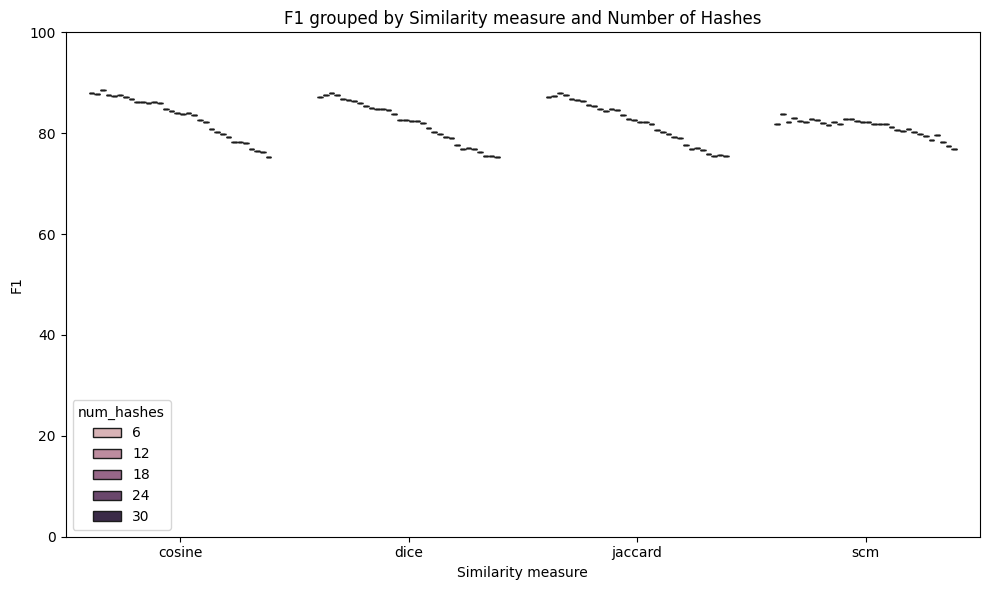

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,88.58
1,dice,1,Precision %,87.81
2,jaccard,1,Precision %,87.64
3,scm,1,Precision %,82.18
4,cosine,2,Precision %,88.77
...,...,...,...,...
379,scm,31,F1 %,77.53
380,cosine,32,F1 %,75.37
381,dice,32,F1 %,75.26
382,jaccard,32,F1 %,75.51


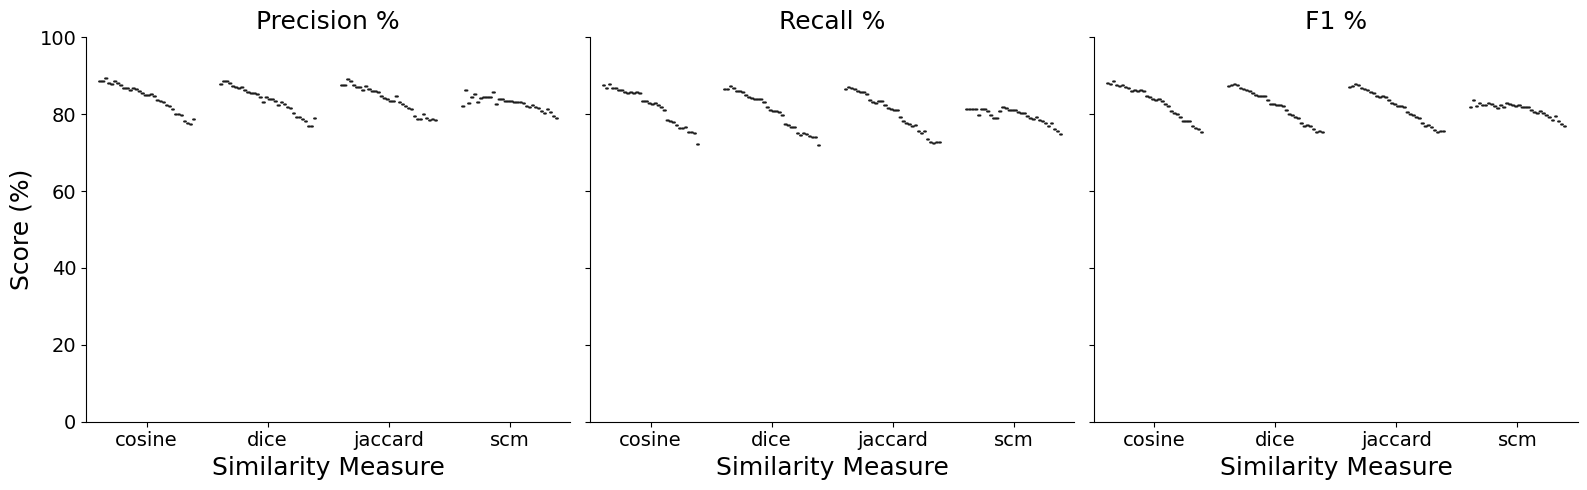

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

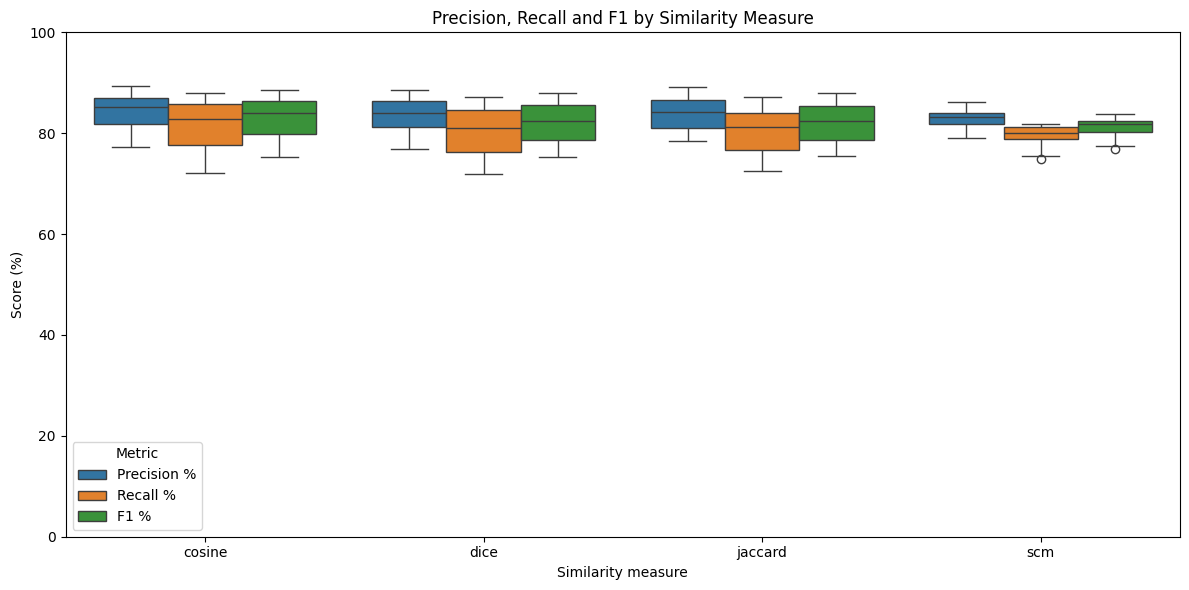

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()